In [3]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

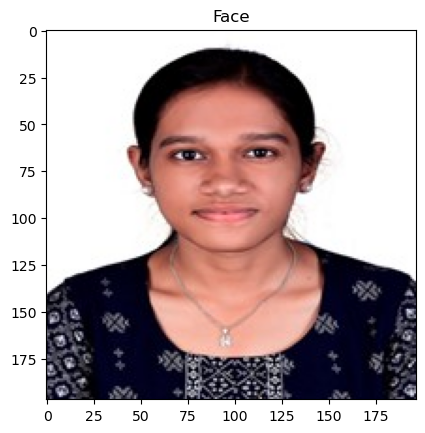

In [4]:
# Load the Face Image
faceImage = cv2.imread('picture1.jpg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [5]:
faceImage.shape

(197, 197, 3)

In [6]:
#resized_faceImage.shape
faceImage.shape

(197, 197, 3)

Text(0.5, 1.0, 'glassPNG')

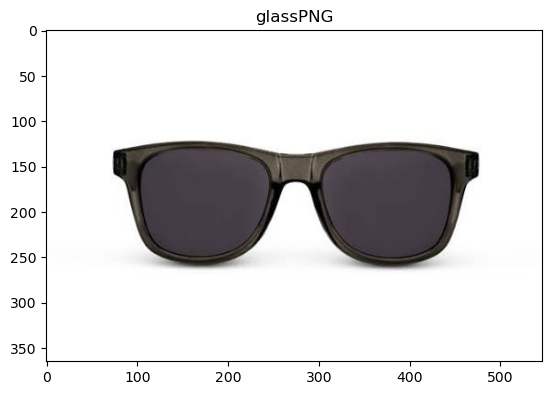

In [7]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglasses.jpg',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [8]:
print("Face dimensions:", faceImage.shape)
print("Sunglasses dimensions:", glassPNG.shape)

Face dimensions: (197, 197, 3)
Sunglasses dimensions: (365, 547, 3)


In [9]:
# Resize sunglasses to fit the face

faceHeight, faceWidth = faceImage.shape[:2]

w = int(faceWidth * 0.75)

originalHeight, originalWidth = glassPNG.shape[:2]
h = int(w * originalHeight / originalWidth)

glassPNG = cv2.resize(glassPNG, (w, h))

# Set sunglasses position
x = (faceWidth - w) // 2
y = 55

print("Image Dimension:", glassPNG.shape)
print("Position:", x, y)

Image Dimension: (98, 147, 3)
Position: 25 55


In [10]:
# Remove white background using grayscale thresholding

glassOriginal = cv2.imread('sunglasses.jpg')
gray = cv2.cvtColor(glassOriginal, cv2.COLOR_BGR2GRAY)

_, glassMask1 = cv2.threshold(
    gray, 235, 255, cv2.THRESH_BINARY_INV
)

# Find sunglasses boundaries
coords = cv2.findNonZero(glassMask1)
x_min, y_min, crop_w, crop_h = cv2.boundingRect(coords)

# Crop sunglasses and mask
glassCrop = glassOriginal[
    y_min:y_min+crop_h, x_min:x_min+crop_w
]

glassMask1 = glassMask1[
    y_min:y_min+crop_h, x_min:x_min+crop_w
]

# Resize proportionally
glass_w = 130
glass_h = int(crop_h * glass_w / crop_w)

glassBGR = cv2.resize(glassCrop, (glass_w, glass_h))
glassMask1 = cv2.resize(glassMask1, (glass_w, glass_h))

# Position sunglasses
x = (faceImage.shape[1] - glass_w) // 2
y = 50

print("Sunglasses:", glassBGR.shape)
print("Mask:", glassMask1.shape)
print("Position:", x, y)

Sunglasses: (45, 130, 3)
Mask: (45, 130)
Position: 33 50


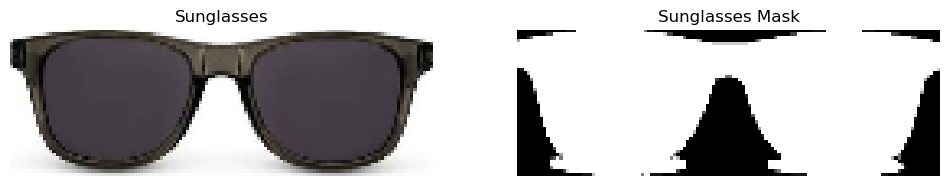

In [11]:
plt.figure(figsize=(12,5))

plt.subplot(121)
plt.imshow(cv2.cvtColor(glassBGR, cv2.COLOR_BGR2RGB))
plt.title("Sunglasses")
plt.axis('off')

plt.subplot(122)
plt.imshow(glassMask1, cmap='gray')
plt.title("Sunglasses Mask")
plt.axis('off')

plt.show()

Sunglasses dimensions: (365, 547, 3)


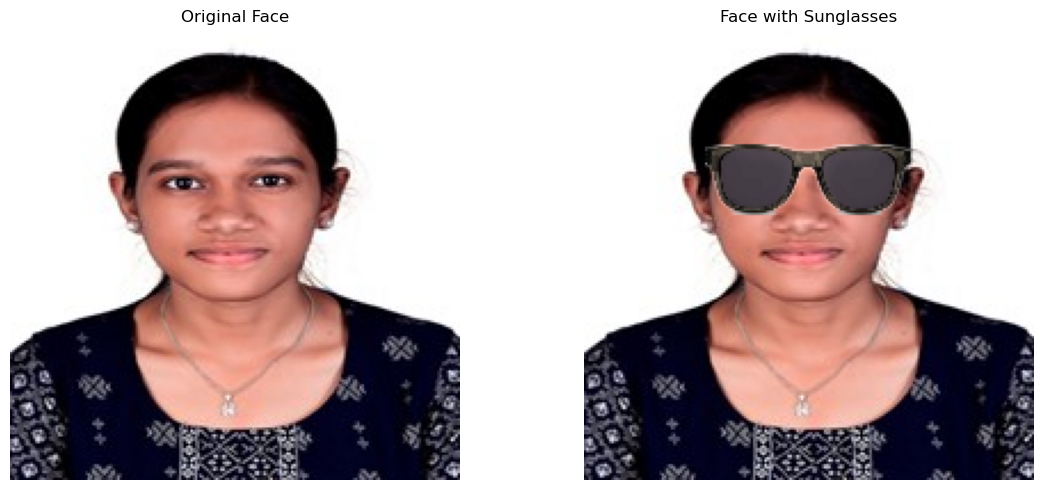

True

In [12]:

# Step 1: Load the NEW sunglasses image
glassOriginal = cv2.imread('sunglasses.jpg')

if glassOriginal is None:
    raise FileNotFoundError("sunglasses.jpg not found!")

print("Sunglasses dimensions:", glassOriginal.shape)


# Step 2: Remove white background
gray = cv2.cvtColor(glassOriginal, cv2.COLOR_BGR2GRAY)

# Create a cleaner mask
_, mask = cv2.threshold(
    gray, 190, 255, cv2.THRESH_BINARY_INV
)

# Remove small unwanted noise
kernel = np.ones((3, 3), np.uint8)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

# Smooth the edges
mask = cv2.GaussianBlur(mask, (3, 3), 0)


# Step 3: Crop unnecessary white space
coords = cv2.findNonZero(
    cv2.threshold(gray, 190, 255, cv2.THRESH_BINARY_INV)[1]
)

x_min, y_min, crop_w, crop_h = cv2.boundingRect(coords)

glassCrop = glassOriginal[
    y_min:y_min+crop_h,
    x_min:x_min+crop_w
]

maskCrop = mask[
    y_min:y_min+crop_h,
    x_min:x_min+crop_w
]


# Step 4: Resize sunglasses
glass_w = 90
glass_h = int(crop_h * glass_w / crop_w)

glassBGR = cv2.resize(glassCrop, (glass_w, glass_h))
glassMask = cv2.resize(maskCrop, (glass_w, glass_h))

# Smooth mask edges
glassMask = cv2.GaussianBlur(glassMask, (3,3), 0)

glassMask = glassMask.astype(np.float32) / 255.0
glassMask = cv2.merge([glassMask, glassMask, glassMask])


# Step 5: Position sunglasses
faceHeight, faceWidth = faceImage.shape[:2]

x = (faceWidth - glass_w) // 2
y = 50


# Step 6: Extract eye region
eyeROI = faceImage[y:y+glass_h, x:x+glass_w]

# Step 7: Alpha blending
eyeROI = eyeROI.astype(np.float32)
glassBGR = glassBGR.astype(np.float32)

result = eyeROI * (1-glassMask) + glassBGR * glassMask

result = np.clip(result, 0, 255).astype(np.uint8)


# Step 8: Overlay sunglasses
faceWithGlassesArithmetic = faceImage.copy()

faceWithGlassesArithmetic[
    y:y+glass_h, x:x+glass_w
] = result


# Step 9: Display output
plt.figure(figsize=(12,5))

plt.subplot(121)
plt.imshow(cv2.cvtColor(faceImage, cv2.COLOR_BGR2RGB))
plt.title("Original Face")
plt.axis('off')

plt.subplot(122)
plt.imshow(cv2.cvtColor(faceWithGlassesArithmetic, cv2.COLOR_BGR2RGB))
plt.title("Face with Sunglasses")
plt.axis('off')

plt.tight_layout()
plt.show()


# Step 10: Save output
cv2.imwrite('face_with_sunglasses.jpg', faceWithGlassesArithmetic)


In [16]:
# Replace the eye ROI with the output from the previous section
faceWithGlassesArithmetic = faceImage.copy()

faceWithGlassesArithmetic[y:y+glass_h, x:x+glass_w] = result
